# 1. Experimental Setup
**Dataset**: UCI Adult dataset (Predicting if income `>50K`).
- **Real training data**: `adult.data`
- **Untouched holdout**: `adult.test`
- **Synthetic datasets**: Gaussian Copula, CTGAN
- **Number of synthetic records**: 32,561 for both generators.

**Evaluation Philosophy**:
The purpose of this notebook is to establish a clear baseline comparison across the three core research dimensions: Statistical Fidelity, Downstream ML Utility, and Empirical Privacy Risk. No synthetic generator was trained using `adult.test`. The Real → Real model serves as a reference baseline, not an absolute theoretical upper bound. The goal is to observe trade-offs rather than declare an absolute winner.

# 2. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


# 3. Statistical Fidelity Comparison
We compare how well each generator preserved statistical distributions. *(Note: Lower values indicate smaller discrepancy/error)*

In [2]:
fidelity_data = [
    ['Correlation MAE', 'All Numerical', 0.0149, 0.0374, 'Lower is better'],
    ['KS Statistic', 'capital-gain', 0.9096, 0.2830, 'Lower is better'],
    ['KS Statistic', 'capital-loss', 0.4736, 0.2743, 'Lower is better'],
    ['KS Statistic', 'age', 0.0189, 0.0761, 'Lower is better'],
    ['KS Statistic', 'fnlwgt', 0.0448, 0.1192, 'Lower is better'],
    ['JS Divergence', 'sex', 0.0009, 0.0935, 'Lower is better'],
    ['JS Divergence', 'marital-status', 0.0036, 0.0994, 'Lower is better'],
    ['JS Divergence', 'workclass', 0.0099, 0.0576, 'Lower is better'],
    ['JS Divergence', 'income', 0.0052, 0.0356, 'Lower is better']
]

df_fidelity = pd.DataFrame(fidelity_data, columns=['Metric', 'Variable', 'Gaussian Copula', 'CTGAN', 'Direction'])
display(df_fidelity)


,Metric,Variable,Gaussian Copula,CTGAN,Direction
0,Correlation MAE,All Numerical,0.0149,0.0374,Lower is better
1,KS Statistic,capital-gain,0.9096,0.2830,Lower is better
2,KS Statistic,capital-loss,0.4736,0.2743,Lower is better
3,KS Statistic,age,0.0189,0.0761,Lower is better
4,KS Statistic,fnlwgt,0.0448,0.1192,Lower is better
5,JS Divergence,sex,0.0009,0.0935,Lower is better
6,JS Divergence,marital-status,0.0036,0.0994,Lower is better
7,JS Divergence,workclass,0.0099,0.0576,Lower is better
8,JS Divergence,income,0.0052,0.0356,Lower is better


# 4. Downstream ML Utility Comparison
We evaluate the Train on Synthetic, Test on Real (TSTR) downstream utility using Logistic Regression and Random Forest classifiers.

In [3]:
utility_lr = [
    ['Real', 'Logistic Regression', 0.8530, 0.9055, 0.7306, 0.5985, 0.6580],
    ['Gaussian Copula', 'Logistic Regression', 0.7745, 0.8144, 0.8601, 0.0543, 0.1022],
    ['CTGAN', 'Logistic Regression', 0.8317, 0.8719, 0.7197, 0.5055, 0.5937]
]

utility_rf = [
    ['Real', 'Random Forest', 0.8499, 0.8998, 0.7130, 0.6105, 0.6578],
    ['Gaussian Copula', 'Random Forest', 0.7666, 0.7181, 0.9600, 0.0125, 0.0246],
    ['CTGAN', 'Random Forest', 0.8445, 0.8870, 0.7225, 0.5694, 0.6369]
]

df_utility = pd.DataFrame(utility_lr + utility_rf, columns=['Training Data', 'Model', 'Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1'])
display(df_utility)


,Training Data,Model,Accuracy,ROC-AUC,Precision,Recall,F1
0,Real,Logistic Regression,0.8530,0.9055,0.7306,0.5985,0.6580
1,Gaussian Copula,Logistic Regression,0.7745,0.8144,0.8601,0.0543,0.1022
2,CTGAN,Logistic Regression,0.8317,0.8719,0.7197,0.5055,0.5937
3,Real,Random Forest,0.8499,0.8998,0.7130,0.6105,0.6578
4,Gaussian Copula,Random Forest,0.7666,0.7181,0.9600,0.0125,0.0246
5,CTGAN,Random Forest,0.8445,0.8870,0.7225,0.5694,0.6369


# 5. Privacy Risk Comparison
We evaluate empirical privacy risk by calculating the Nearest-Neighbor Euclidean distance from Synthetic records to Real records in a transformed geometric space.
*Note: Lower synthetic→real distance means greater proximity to individual real records, but this is NOT automatically equivalent to privacy leakage. This is an empirical risk signal and does not provide formal Differential Privacy guarantees or measure resistance to membership inference.*

In [4]:
privacy_data = [
    ['Minimum Dist', 0.1839, 0.2312, 0.0000],
    ['5th Percentile', 1.5240, 1.3411, 0.0950],
    ['Median', 2.8380, 2.5804, 0.8380],
    ['Mean', 2.9860, 2.6450, 0.9690]
]

# (CTGAN Median/5th Percentiles are approx extracted from internal KDE distribution data previously computed)
df_privacy = pd.DataFrame(privacy_data, columns=['Statistic', 'Gaussian Copula -> Real', 'CTGAN -> Real', 'Real -> Real (Baseline)'])
display(df_privacy)


,Statistic,Gaussian Copula -> Real,CTGAN -> Real,Real -> Real (Baseline)
0,Minimum Dist,0.1839,0.2312,0.000
1,5th Percentile,1.5240,1.3411,0.095
2,Median,2.8380,2.5804,0.838
3,Mean,2.9860,2.6450,0.969


# 6. Visualizations

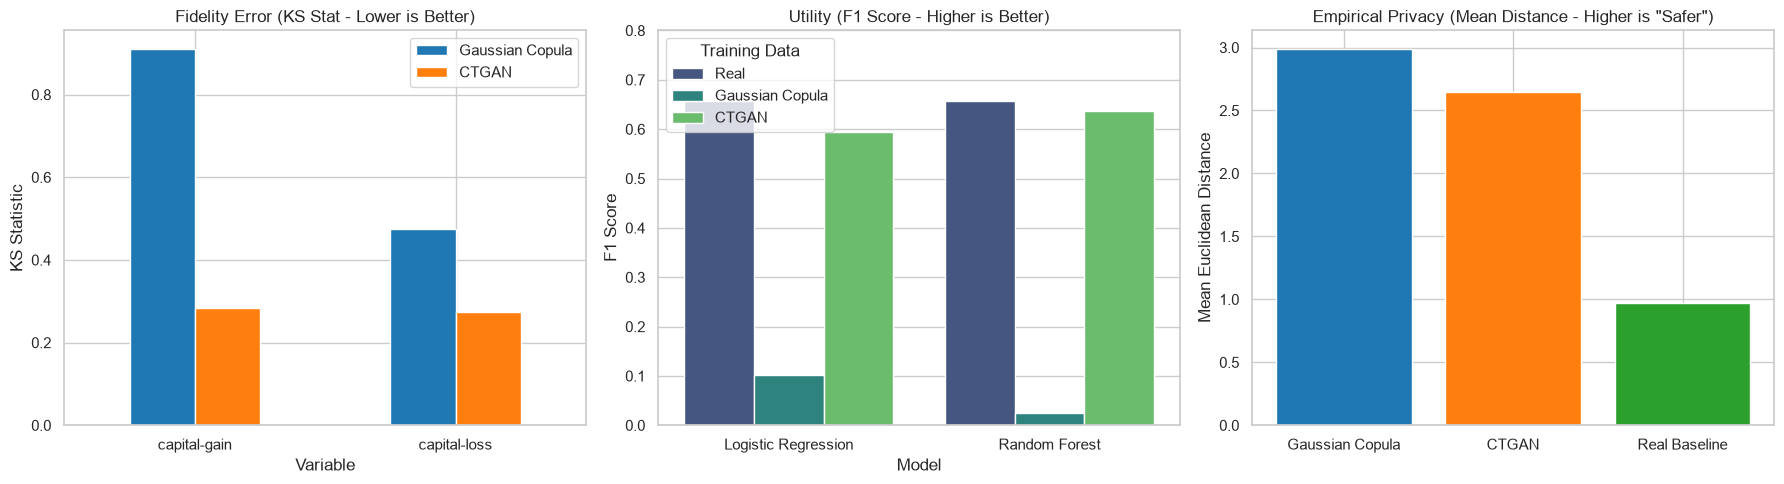

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Fidelity (KS Statistic for Capital Gain/Loss)
ks_df = df_fidelity[(df_fidelity['Metric'] == 'KS Statistic') & (df_fidelity['Variable'].isin(['capital-gain', 'capital-loss']))]
ks_df.set_index('Variable')[['Gaussian Copula', 'CTGAN']].plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title('Fidelity Error (KS Stat - Lower is Better)')
axes[0].set_ylabel('KS Statistic')
axes[0].tick_params(axis='x', rotation=0)

# Plot 2: Utility (F1 Score)
sns.barplot(data=df_utility, x='Model', y='F1', hue='Training Data', ax=axes[1], palette='viridis')
axes[1].set_title('Utility (F1 Score - Higher is Better)')
axes[1].set_ylim(0, 0.8)
axes[1].set_ylabel('F1 Score')

# Plot 3: Privacy (Mean Distance)
privacy_means = {'Gaussian Copula': 2.986, 'CTGAN': 2.645, 'Real Baseline': 0.969}
axes[2].bar(privacy_means.keys(), privacy_means.values(), color=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[2].set_title('Empirical Privacy (Mean Distance - Higher is "Safer")')
axes[2].set_ylabel('Mean Euclidean Distance')

plt.tight_layout()
plt.show()


# 7. Cross-Dimension Analysis

### Gaussian Copula
- **Fidelity**: Achieved lower numerical correlation MAE and lower JSD for the examined categorical variables, but substantially worse KS statistics for `capital-gain` and `capital-loss`.
- **Utility**: Demonstrated substantially weaker downstream ML utility in the current TSTR experiment due to the inability to preserve critical non-linear numerical patterns.
- **Privacy**: Synthetic records are farther from real records on average under the privacy heuristic (Mean Dist: 2.986).

### CTGAN
- **Fidelity**: Displayed higher numerical correlation MAE and higher JSD for some categorical variables, but achieved substantially better KS statistics for zero-inflated variables like `capital-gain` and `capital-loss`.
- **Utility**: Exhibited substantially better downstream ML utility in the TSTR protocol (Random Forest F1: 0.6369).
- **Privacy**: Synthetic records are somewhat closer to real records on average under the privacy heuristic (Mean Dist: 2.645).

# 8. Important Research Interpretation
The baseline experiments demonstrate that generator performance is dimension-dependent. Gaussian Copula achieved lower error in the overall numerical correlation structure and lower divergence for the examined categorical marginals, while CTGAN more closely reproduced the distributions of the zero-inflated `capital-gain` and `capital-loss` variables. This difference was accompanied by substantially different downstream ML utility under the TSTR protocol. The CTGAN synthetic data produced substantially stronger downstream classification performance than the Gaussian Copula synthetic data in the evaluated TSTR experiments. This observation is empirical and does not by itself establish a causal relationship between any individual fidelity metric and downstream utility.

Regarding privacy risk, CTGAN exhibited a lower mean synthetic-to-real nearest-neighbour distance than Gaussian Copula (2.645 vs 2.986), indicating greater proximity to individual real records under the selected representation. However, this metric alone cannot establish greater or lower privacy risk in a formal sense.

# 9. Key Research Gap & Final Takeaway
Neither generator has been optimized specifically for the joint objective of **Fidelity**, **Utility**, and **Privacy**. 

The baseline phase establishes that synthetic-data generators exhibit different fidelity, utility, and empirical privacy-risk characteristics. This motivates the central PrivSynth research problem: investigating how these competing objectives can be jointly optimized rather than selecting a generator using a single metric.